In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib import rcParams
plt.rcParams['figure.dpi'] = 200
plt.rcParams['font.family'] = 'serif'
plt.rcParams['figure.figsize'] = [10, 5]

### Read the data

In [129]:
jointDF = pd.read_csv(
    "data.txt",
    sep=r"[:,]\s*",
    engine="python",
    header=None,
    usecols=[1, 3, 5],
    names=["A", "D", "F"],
)
calcDF = pd.read_csv(
    "sixbar_joint_angles.csv",
    header=0,
)
print(jointDF)
print(calcDF)

               A          D          F
0    -256.000000   6.945055  28.835165
1    -252.747253   8.703297  28.835165
2    -249.230769  10.637363  28.835165
3    -245.890110  12.483516  28.835165
4    -243.780220  13.714286  28.835165
..           ...        ...        ...
691  1767.560440  21.978022  -2.285714
692  1767.560440  21.978022  -2.373626
693  1767.560440  21.978022  -2.285714
694  1767.560440  21.978022  -2.285714
695  1767.560440  21.978022  -2.285714

[696 rows x 3 columns]
     th2_deg (A->B)  th3_deg (B->C)  th4_deg (C->D)  th5_deg (M->N)  \
0                 0        -78.6401       -162.5020       -165.3484   
1                 1        -78.8016       -161.9676       -164.9141   
2                 2        -78.9591       -161.4305       -164.4808   
3                 3        -79.1126       -160.8907       -164.0487   
4                 4        -79.2621       -160.3485       -163.6177   
..              ...             ...             ...             ...   
356        

### Make data fit to each other + calcualte error

In [162]:
start = 0
end = start + 360

shift = 101
calcA = calcDF['joint_A_deg (ground->AB)']
calcD = calcDF['joint_D_deg (ground->DC)']
calcF = calcDF['joint_F_deg (ground->FN)']
calcD = np.roll(calcD, shift)
calcF = np.roll(calcF, shift)

#set the starting value to 0 like the physical model does
calcD = calcD - calcD[0]
calcF = calcF - calcF[0]

errAD = np.interp(jointDF['A'], calcA, calcD) - jointDF['D']
errAF = np.interp(jointDF['A'], calcA, calcF) - jointDF['F']


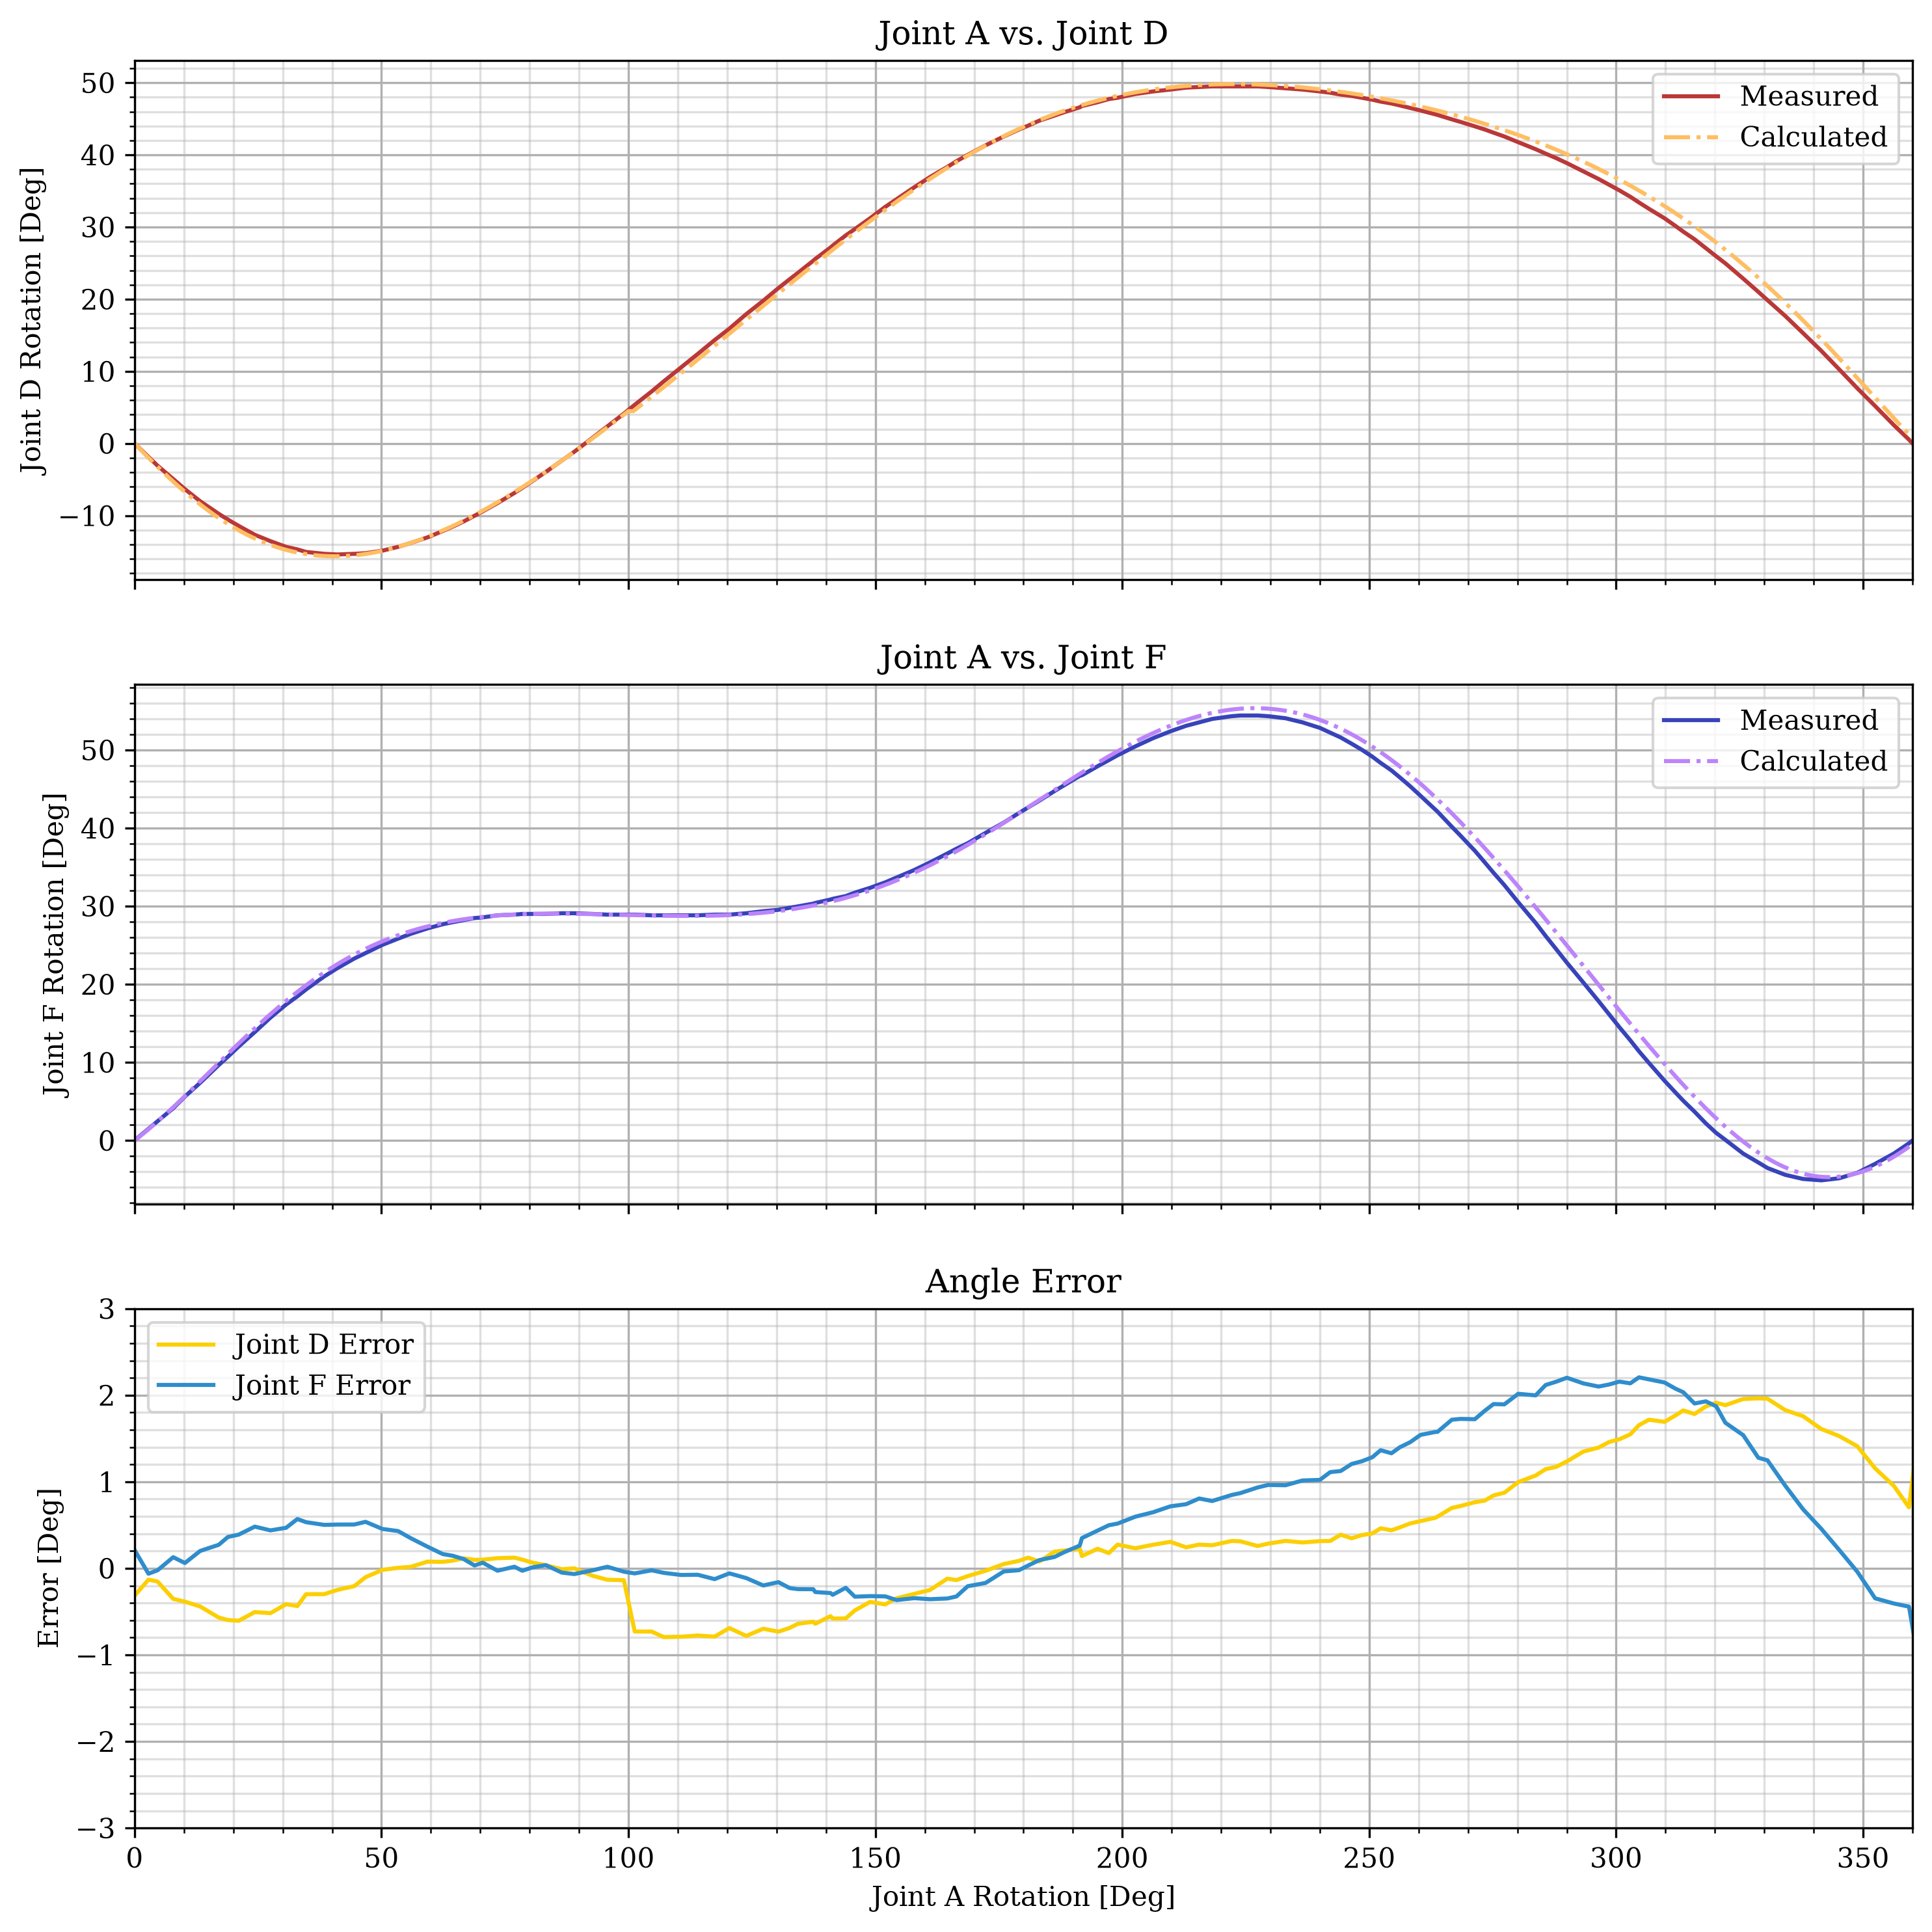

In [174]:
fig, (ax1, ax2, ax3) = plt.subplots(3,1, figsize=(10,10), sharex=True)
ax1.plot(jointDF['A'],jointDF['D'], color = '#BA3838', label = "Measured")
ax1.plot(calcA, calcD, linestyle = 'dashdot', color = '#FFBE63', label = "Calculated")
ax1.minorticks_on()
ax1.grid()
ax1.grid(which='minor', alpha=0.40)
ax1.set_title("Joint A vs. Joint D")
ax1.set_ylabel("Joint D Rotation [Deg]")
ax1.legend(loc='best')
ax1.set_xlim(start,end)

ax2.plot(jointDF['A'],jointDF['F'], color = '#3843BA', label = "Measured")
ax2.plot(calcA, calcF, linestyle = 'dashdot', color = '#BC84FA', label = "Calculated")
ax2.minorticks_on()
ax2.grid()
ax2.grid(which='minor', alpha=0.40)
ax2.set_title("Joint A vs. Joint F")
ax2.set_ylabel("Joint F Rotation [Deg]")
ax2.set_xlim(start,end)
ax2.legend(loc='best')

ax3.plot(jointDF['A'],errAD, color = '#fccf03', label = "Joint D Error")
ax3.plot(jointDF['A'], errAF, color = '#2f8dcc', label = "Joint F Error")
ax3.minorticks_on()
ax3.grid()
ax3.grid(which='minor', alpha=0.40)
ax3.set_title("Angle Error")
ax3.set_xlabel("Joint A Rotation [Deg]")
ax3.set_ylabel("Error [Deg]")
ax3.set_xlim(start,end)
ax3.set_ylim(-3,3)
ax3.legend(loc='best')

plt.tight_layout(h_pad=2)